In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt

uploaded = files.upload()

df = pd.read_csv("train.csv")

print("Kích thước dữ liệu:", df.shape)
print("Các cột:", df.columns.tolist())
print(df[["Id", "SalePrice"]].head())


Saving train.csv to train.csv
Kích thước dữ liệu: (1460, 81)
Các cột: ['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorch

In [2]:

y = df["SalePrice"].astype(float).reset_index(drop=True)

split_idx = int(len(y) * 0.70)

train = y.iloc[:split_idx]
test = y.iloc[split_idx:]

print(f"Tổng số dòng: {len(y)}")
print(f"Số dòng train: {len(train)} ({len(train)/len(y):.0%})")
print(f"Số dòng test: {len(test)} ({len(test)/len(y):.0%})")


Tổng số dòng: 1460
Số dòng train: 1021 (70%)
Số dòng test: 439 (30%)


In [3]:

window = 5

history = list(train.values)
ma_predictions = []

for _ in range(len(test)):
    pred = np.mean(history[-window:])
    ma_predictions.append(pred)
    history.append(pred)

ma_predictions = np.array(ma_predictions)

print("MA hoàn tất.")
print("5 giá trị dự báo đầu tiên:", ma_predictions[:5])


MA hoàn tất.
5 giá trị dự báo đầu tiên: [187998.     184997.6    184497.12   189396.544  184577.8528]


In [4]:

ses_model = SimpleExpSmoothing(
    train,
    initialization_method="estimated"
).fit(optimized=True)

ses_predictions = ses_model.forecast(len(test)).to_numpy()

print("SES hoàn tất.")
print("Alpha tối ưu:", ses_model.params["smoothing_level"])
print("5 giá trị dự báo đầu tiên:", ses_predictions[:5])


SES hoàn tất.
Alpha tối ưu: 1.4901161193847656e-08
5 giá trị dự báo đầu tiên: [181711.1497057 181711.1497057 181711.1497057 181711.1497057
 181711.1497057]


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


In [5]:

holt_model = Holt(
    train,
    initialization_method="estimated",
    damped_trend=False
).fit(optimized=True)

holt_predictions = holt_model.forecast(len(test)).to_numpy()

print("Holt hoàn tất.")
print("Alpha:", holt_model.params["smoothing_level"])
print("Beta:", holt_model.params["smoothing_trend"])
print("5 giá trị dự báo đầu tiên:", holt_predictions[:5])


Holt hoàn tất.
Alpha: 0.013793426991337815
Beta: 0.0
5 giá trị dự báo đầu tiên: [169813.00138263 169782.35458812 169751.70779362 169721.06099911
 169690.41420461]


In [6]:

models = {
    "Moving Average (MA)": ma_predictions,
    "Single Exponential Smoothing (SES)": ses_predictions,
    "Holt (2 parameters)": holt_predictions
}

results = []

for name, predictions in models.items():
    mae = mean_absolute_error(test, predictions)
    rmse = np.sqrt(mean_squared_error(test, predictions))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)

print("=== SO SÁNH KẾT QUẢ ===")
display(results_df.style.format({
    "MAE": "{:,.2f}",
    "RMSE": "{:,.2f}"
}))

print("Mô hình có RMSE thấp nhất:", results_df.iloc[0]["Model"])


=== SO SÁNH KẾT QUẢ ===


,Model,MAE,RMSE
0,Single Exponential Smoothing (SES),"55,955.56","78,399.33"
1,Moving Average (MA),"57,177.41","78,655.32"
2,Holt (2 parameters),"53,738.54","80,091.65"


Mô hình có RMSE thấp nhất: Single Exponential Smoothing (SES)


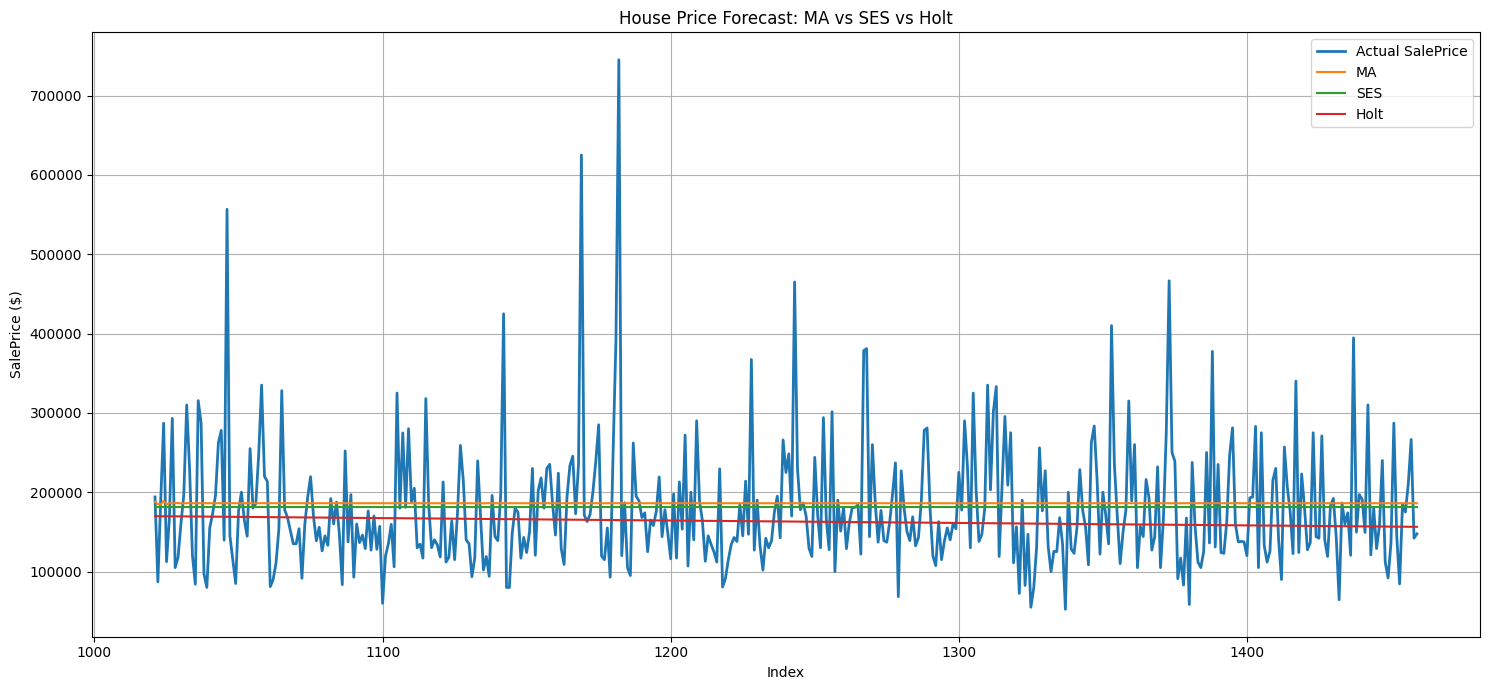

In [7]:

plt.figure(figsize=(15, 7))

plt.plot(
    test.index,
    test.values,
    label="Actual SalePrice",
    linewidth=2
)

plt.plot(test.index, ma_predictions, label="MA")
plt.plot(test.index, ses_predictions, label="SES")
plt.plot(test.index, holt_predictions, label="Holt")

plt.title("House Price Forecast: MA vs SES vs Holt")
plt.xlabel("Index")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [8]:

forecast_df = pd.DataFrame({
    "Actual_SalePrice": test.to_numpy(),
    "MA_Prediction": ma_predictions,
    "SES_Prediction": ses_predictions,
    "Holt_Prediction": holt_predictions
})

results_df.to_csv("model_comparison.csv", index=False)
forecast_df.to_csv("house_price_forecasts.csv", index=False)

files.download("model_comparison.csv")
files.download("house_price_forecasts.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>